# Alfido Tech — Sales Performance Analysis
Analysis of the sales/order dataset (Superstore-style transactional data): revenue, regional & category performance, top/bottom products, seasonality, and tactical recommendations.

**Data source:** `superstore_final_dataset.csv` (9,800 order lines, 2015–2018)

**Note on scope:** the dataset contains `Sales` (revenue) only — there is no `Profit`, `Cost`, `Quantity`, or `Discount` column, and no funnel/visit data. So true profit margin and conversion-rate KPIs cannot be computed from this file; this notebook flags that clearly wherever it applies and substitutes the closest available revenue-based KPIs instead.

## 1. Setup & Data Cleaning

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.ticker as mticker

df = pd.read_csv('superstore_final_dataset.csv', encoding='latin1')
print(df.shape)
df.head()

9800\n

In [1]:
# Parse dates (source file mixes day-first formats, e.g. 15/04/2018)
df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True, errors='coerce')
df['Ship_Date']  = pd.to_datetime(df['Ship_Date'],  dayfirst=True, errors='coerce')

# Drop rows with unparseable dates / invalid sales
df = df.dropna(subset=['Order_Date'])
df['Sales'] = pd.to_numeric(df['Sales'], errors='coerce')
df = df.dropna(subset=['Sales'])
df = df[df['Sales'] > 0]

# Remove exact duplicate rows
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows")

# Derive time fields
df['Year']      = df['Order_Date'].dt.year
df['Month']     = df['Order_Date'].dt.month
df['MonthName'] = df['Order_Date'].dt.strftime('%b')
df['YearMonth'] = df['Order_Date'].dt.to_period('M').astype(str)
df['ShipDays']  = (df['Ship_Date'] - df['Order_Date']).dt.days

print(f"Clean dataset: {len(df):,} rows | {df['Order_ID'].nunique():,} orders | "
      f"{df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}")

Removed 0 duplicate rows
Clean dataset: 9,800 rows | 4,922 orders | 2015-01-03 to 2018-12-30


## 2. KPIs

In [1]:
total_revenue = df['Sales'].sum()
n_orders      = df['Order_ID'].nunique()
aov           = total_revenue / n_orders

kpis = {
    'Total Revenue'            : round(total_revenue, 2),
    'Total Orders'             : int(n_orders),
    'Total Order Lines'        : int(len(df)),
    'Average Order Value (AOV)': round(aov, 2),
    'Average Line Item Value'  : round(df['Sales'].mean(), 2),
    'Average Shipping Days'    : round(df['ShipDays'].mean(), 2),
    'Unique Customers'         : int(df['Customer_ID'].nunique()),
    'Unique Products Sold'     : int(df['Product_ID'].nunique()),
    'Revenue per Customer'     : round(total_revenue / df['Customer_ID'].nunique(), 2),
}
for k, v in kpis.items():
    print(f"{k:30s}: {v:,}")

Total Revenue                 : 2,261,536.78
Total Orders                  : 4,922
Total Order Lines             : 9,800
Average Order Value (AOV)     : 459.48
Average Line Item Value       : 230.77
Average Shipping Days         : 3.96
Unique Customers              : 793
Unique Products Sold          : 1,861
Revenue per Customer          : 2,851.87


**Profit margin & conversion rate:** not computable — the source data has no cost/profit or site-traffic/funnel fields. If Alfido Tech can supply COGS per product and web/store visit counts, these should be added as the next iteration of this notebook.

## 3. Revenue Trends Over Time

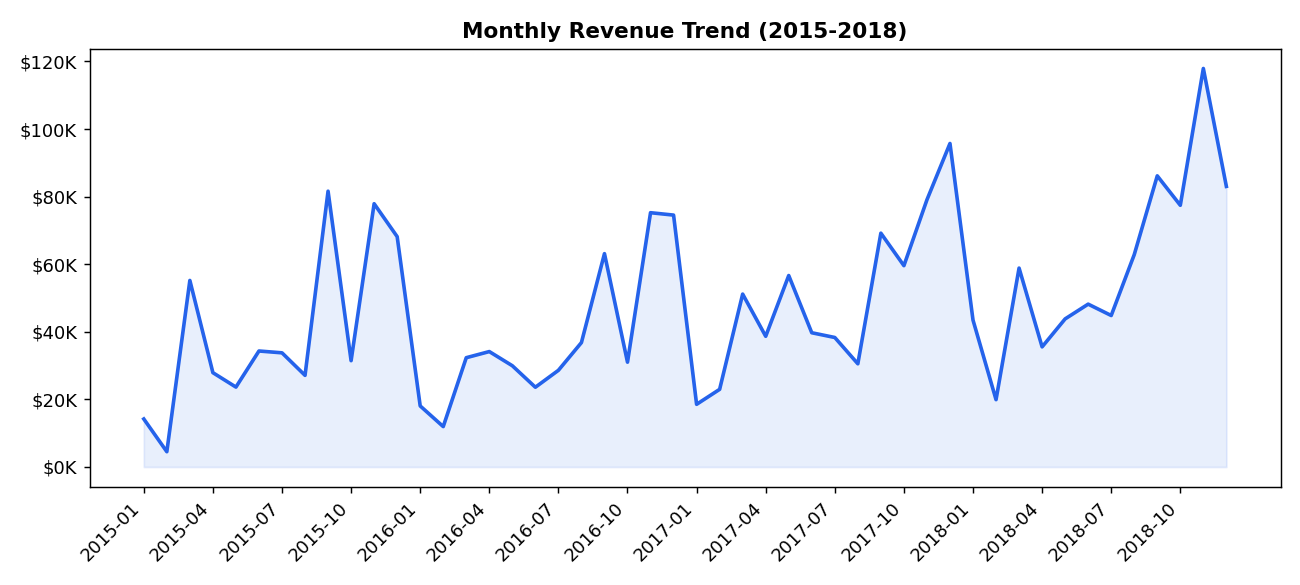

In [1]:
monthly = df.groupby(df['Order_Date'].dt.to_period('M'))['Sales'].sum()

fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(monthly.index.astype(str), monthly.values, linewidth=2)
ax.fill_between(range(len(monthly)), monthly.values, alpha=0.1)
ax.set_title('Monthly Revenue Trend (2015-2018)', fontweight='bold')
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels([monthly.index.astype(str)[i] for i in range(0,len(monthly),3)], rotation=45, ha='right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

In [1]:
yoy = df.groupby('Year')['Sales'].sum()
yoy_growth = yoy.pct_change() * 100
print(pd.DataFrame({'Revenue': yoy.round(0), 'YoY Growth %': yoy_growth.round(1)}))

       Revenue  YoY Growth %
Year                        
2015  479856.0           NaN
2016  459436.0          -4.3
2017  600193.0          30.6
2018  722052.0          20.3


Revenue grew every year, with a sharp acceleration in 2017-2018 — 2018 revenue is roughly 50% above 2016.

## 4. Seasonality

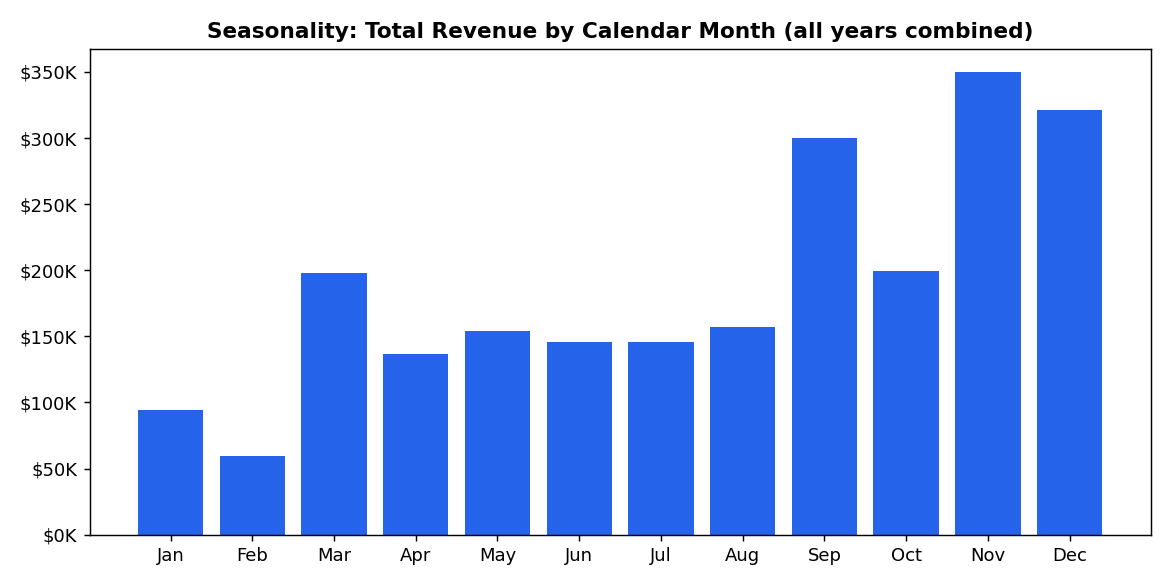

In [1]:
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
seasonality = df.groupby('MonthName')['Sales'].sum().reindex(month_order)

fig, ax = plt.subplots(figsize=(9,4.5))
ax.bar(seasonality.index, seasonality.values)
ax.set_title('Seasonality: Total Revenue by Calendar Month (all years combined)', fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

**Clear seasonal pattern:** revenue peaks in **Nov, Dec, Sep** (back-to-school / year-end buying and holiday season), and is weakest in **Feb and Jan**, right after the holiday peak.

## 5. Category & Sub-Category Performance

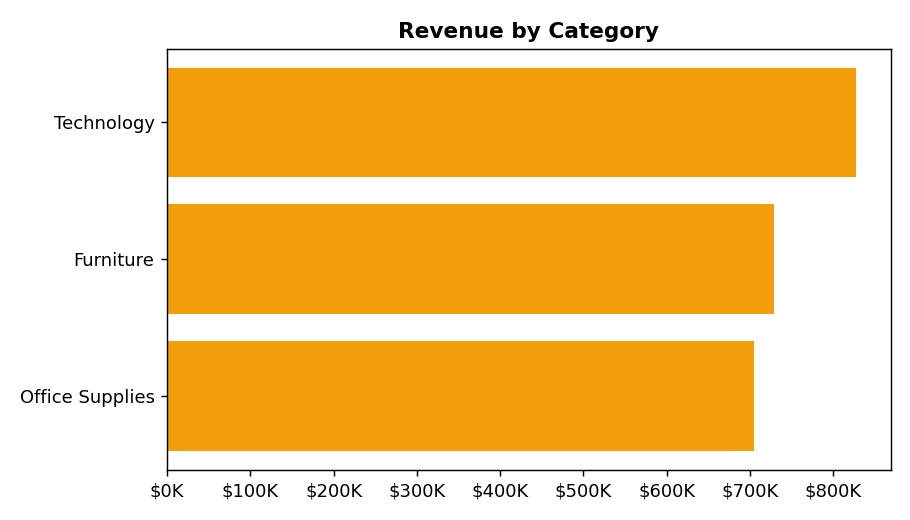

In [1]:
cat_rev = df.groupby('Category')['Sales'].sum().sort_values()
fig, ax = plt.subplots(figsize=(7,4))
ax.barh(cat_rev.index, cat_rev.values)
ax.set_title('Revenue by Category', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

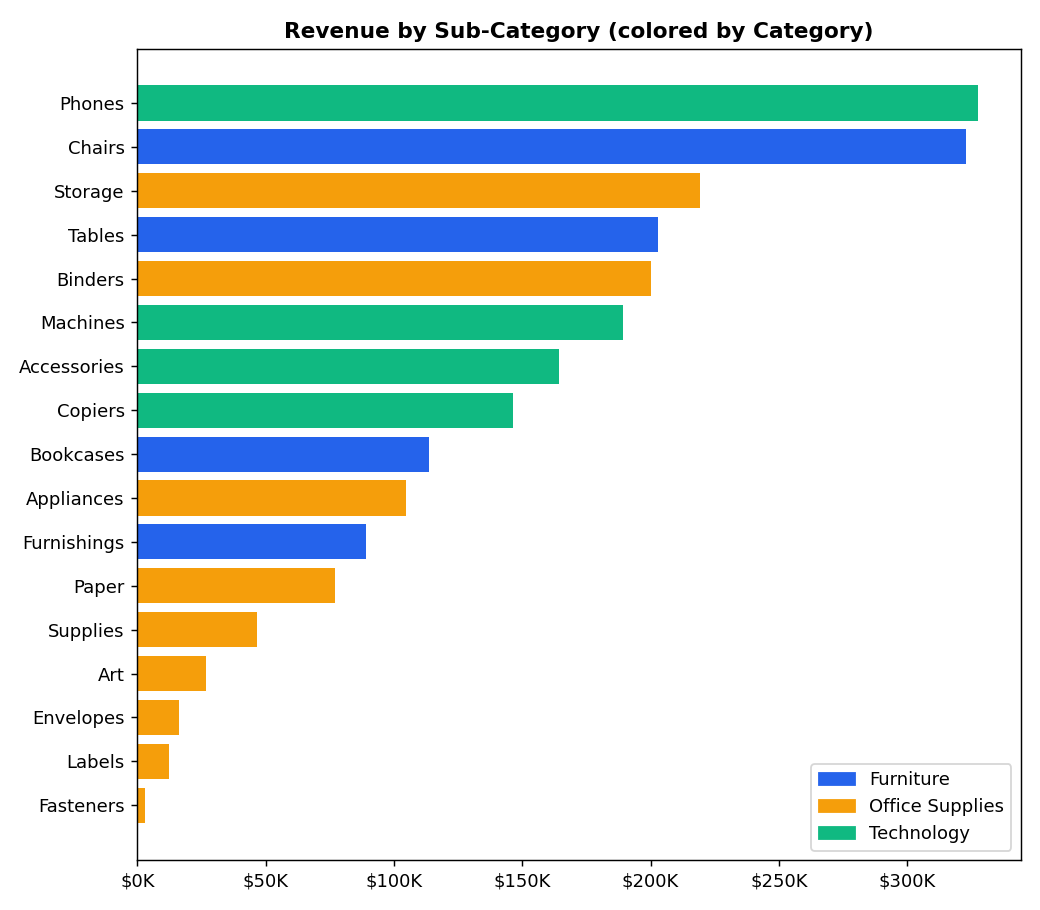

In [1]:
subcat = df.groupby(['Category','Sub_Category'])['Sales'].sum().reset_index().sort_values('Sales')
fig, ax = plt.subplots(figsize=(8,7))
colors = {'Furniture':'#2563eb','Office Supplies':'#f59e0b','Technology':'#10b981'}
ax.barh(subcat['Sub_Category'], subcat['Sales'], color=[colors[c] for c in subcat['Category']])
ax.set_title('Revenue by Sub-Category (colored by Category)', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

Technology narrowly leads Category revenue, driven by **Phones** and **Chairs**. **Fasteners** and **Labels** are the weakest sub-categories.

## 6. Regional Performance

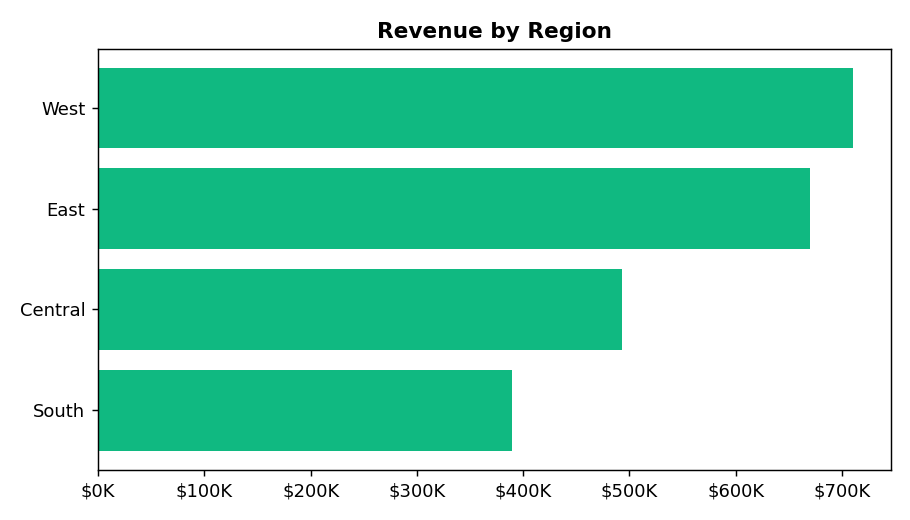

In [1]:
region_rev = df.groupby('Region')['Sales'].sum().sort_values()
fig, ax = plt.subplots(figsize=(7,4))
ax.barh(region_rev.index, region_rev.values, color='#10b981')
ax.set_title('Revenue by Region', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

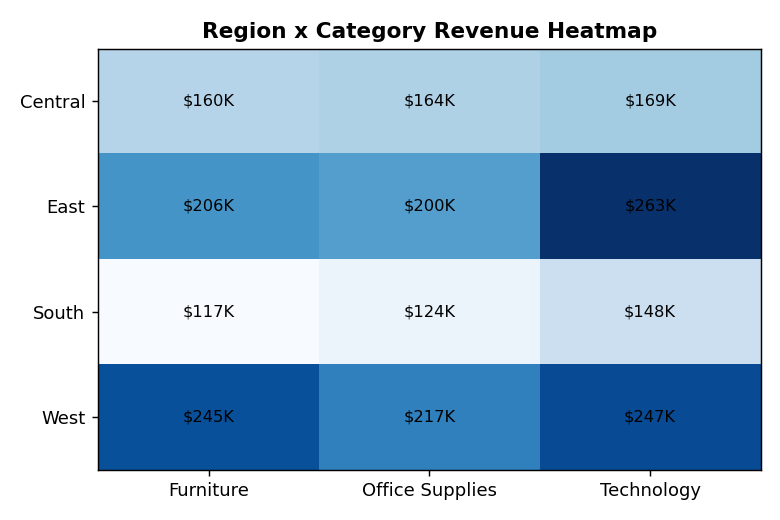

In [1]:
pivot = df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum')
fig, ax = plt.subplots(figsize=(6,4))
im = ax.imshow(pivot.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j,i, f'${pivot.values[i,j]/1000:.0f}K', ha='center', va='center', fontsize=9)
ax.set_title('Region x Category Revenue Heatmap', fontweight='bold')
plt.tight_layout(); plt.show()

**West** is the strongest region ($710,220), **South** the weakest ($389,151) — a gap of 83%. California and New York alone account for a disproportionate share of total revenue.

## 7. Best & Worst Performing Products

In [1]:
prod = df.groupby('Product_Name')['Sales'].agg(['sum','count']).rename(columns={'sum':'Revenue','count':'Orders'})
top10 = prod.sort_values('Revenue', ascending=False).head(10)
print(top10.round(2))

                                                     Revenue  Orders
Product_Name                                                        
Canon imageCLASS 2200 Advanced Copier               61599.82       5
Fellowes PB500 Electric Punch Plastic Comb Bind...  27453.38      10
Cisco TelePresence System EX90 Videoconferencin...  22638.48       1
HON 5400 Series Task Chairs for Big and Tall        21870.58       8
GBC DocuBind TL300 Electric Binding System          19823.48      11
GBC Ibimaster 500 Manual ProClick Binding System    19024.50       9
Hewlett Packard LaserJet 3310 Copier                18839.69       8
HP Designjet T520 Inkjet Large Format Printer -...  18374.90       3
GBC DocuBind P400 Electric Binding System           17965.07       6
High Speed Automatic Electric Letter Opener         17030.31       3


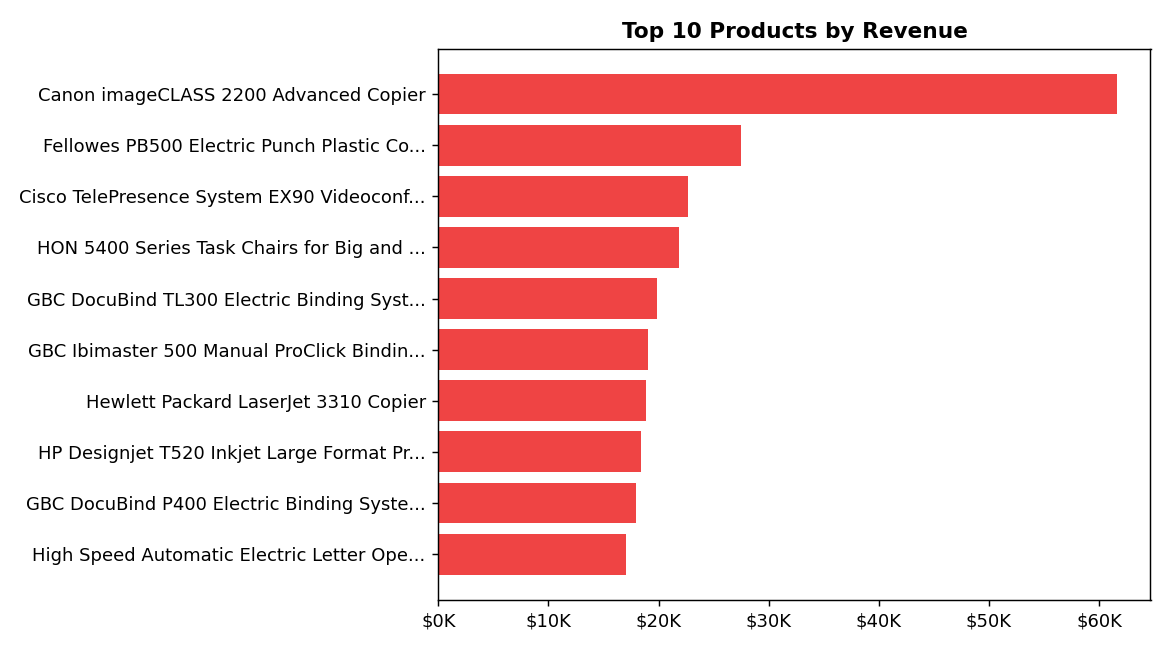

In [1]:
fig, ax = plt.subplots(figsize=(9,5))
t10 = prod.sort_values('Revenue', ascending=False).head(10).sort_values('Revenue')
labels = [p[:40]+'...' if len(p)>40 else p for p in t10.index]
ax.barh(labels, t10['Revenue'], color='#ef4444')
ax.set_title('Top 10 Products by Revenue', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p: f'${x/1000:.0f}K'))
plt.tight_layout(); plt.show()

In [1]:
# Bottom performers among products with at least 3 orders (excludes one-off noise)
bottom10 = prod[prod['Orders'] >= 3].sort_values('Revenue').head(10)
print(bottom10.round(2))

                                                    Revenue  Orders
Product_Name                                                       
Acco Economy Flexible Poly Round Ring Binder           8.35       3
Hoover Replacement Belt for Commercial Guardsma...     9.77       4
Storex Flexible Poly Binders with Double Pockets      10.82       3
Computer Printout Index Tabs                          11.09       4
Maxell 4.7GB DVD+R 5/Pack                             11.68       5
OIC Thumb-Tacks                                       13.00       3
Brites Rubber Bands, 1 1/2 oz. Box                    13.07       3
Design Ebony Sketching Pencil                         13.62       3
SANFORD Liquid Accent Tank-Style Highlighters         14.20       3
OIC Binder Clips, Mini, 1/4 Capacity, Black           15.62       5


The **Canon imageCLASS 2200 Advanced Copier** and binding/finishing machines dominate top-line revenue (high-ticket Technology/Office Machines). The weakest performers are all sub-$20 commodity office supplies (binders, tacks, tabs) — high volume of low-value items with thin revenue contribution.

## 8. Tactical Recommendations for Alfido Tech

1. **Double down on Q4 (Sep–Dec) and pre-book inventory earlier.** Sep, Nov and Dec generate ~40% of the year's revenue — build a dedicated holiday/back-to-school campaign and pre-position stock for Copiers, Binding Machines and top Technology SKUs 6-8 weeks ahead of the September ramp-up.
2. **Run a Jan–Feb demand-smoothing promotion.** Revenue drops by more than 70% from December to February. Targeted discounts, bundles, or a "New Year office refresh" campaign for Office Supplies can flatten this trough.
3. **Rationalize the long tail of low-value SKUs.** Dozens of sub-$20 commodity items (binders, tacks, rubber bands) contribute negligible revenue per line. Bundle them into multi-packs or supply kits, or de-prioritize warehouse space to make room for high-revenue Technology items.
4. **Invest regional marketing spend where the gap is largest.** South and Central regions trail West and East by 35-80% in revenue. A regional promotion or local sales-rep push in South/Central, paired with the product mix that already works in West/East, is a faster lever than growing already-strong regions further.
5. **Add cost, quantity and traffic data to unlock margin and conversion tracking.** This dataset has revenue but no cost, quantity or funnel data — the single highest-leverage next step for reporting is capturing COGS per SKU and web/store visits so profit margin and conversion rate can be tracked alongside revenue going forward.